# Asignar átomos a sitios: el algoritmo húngaro, el exponente y los cruces

**Pregunta:** ¿Cómo se asignan los átomos cargados a los sitios vacíos de un bloque objetivo de modo que el bloque termine sin defectos y los caminos rectos de los átomos no se crucen?

- Nivel: 2, el método en la práctica.
- Requisitos previos: `03-gerchberg-saxton/02-weights-for-uniformity`, porque la secuencia que sigue se construye con hologramas de GS ponderado.
- Tiempo de lectura: unos 25 minutos. El notebook se ejecuta en cerca de 30 segundos.

## Objetivos

En un arreglo de pinzas los átomos se cargan al azar: cada sitio contiene un átomo con una probabilidad cercana a un medio, y un computador cuántico o un simulador necesita un bloque de sitios completamente lleno. El remedio es leer qué sitios están cargados y mover los átomos de los sitios sobrantes a los vacíos con las mismas trampas que los sostienen. Decidir quién va adónde es la primera mitad de ese ordenamiento, y no necesita luz alguna. Al terminar puedes:

- enunciar la asignación como un emparejamiento de costo mínimo, y decir qué cambia el exponente del costo;
- contar los pares de caminos rectos que se cruzan, y leer una tabla que compara exponentes;
- leer lo que construye M16 a partir de la misma asignación: el número de pasos y de trampas en movimiento;
- decir qué garantiza el ordenamiento, y cuáles de sus garantías dependen de la carga que se sorteó.

El notebook `07-feedback-and-dynamics/04-moving-atoms-by-linear-phase-interpolation` toma la segunda mitad, la luz que mueve los átomos.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.cases.library import random_loading
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.forward import point_trap_fields
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.control import m16_rearrangement
from pipeline.model.holo.methods.control.m16_rearrangement import assign, count_crossings

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C10 de `data/examples/cases.json`: un arreglo de 10 x 10 sitios con un espaciado de cerca de 8 bins focales, una probabilidad de carga de 0,55 y un bloque de 36 sitios objetivo en el centro.

- Propietario: este repositorio; el caso es sintético, y la carga se sortea con el generador portátil y la semilla del registro.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C10 (el bloque `rearrangement` lleva la probabilidad de carga, los identificadores objetivo y el exponente).

In [2]:
# caso C10: un arreglo de 10 x 10 sitios, cargado al azar, y un bloque de 6 x 6 por llenar
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C10"]
setup = build.setup_of(rec)
sites = {t["id"]: t for t in rec["target"]["traps"]}
loaded = random_loading(rec)
wanted = rec["rearrangement"]["target_ids"]
empty = sorted(set(wanted) - set(loaded))
surplus = sorted(set(loaded) - set(wanted))
print(rec["case_id"], "|", len(sites), "sitios | probabilidad de carga", rec["rearrangement"]["loading_p"])
print(f"átomos cargados: {len(loaded)} | sitios objetivo: {len(wanted)} | "
      f"sitios objetivo vacíos: {len(empty)} | átomos sobrantes: {len(surplus)}")

C10_rearrangement | 100 sitios | probabilidad de carga 0.55
átomos cargados: 52 | sitios objetivo: 36 | sitios objetivo vacíos: 16 | átomos sobrantes: 32


La carga es un número uniforme por sitio comparado con la probabilidad, así que es la misma en cada corrida. La figura muestra qué sitios contienen un átomo y cuáles de los 36 sitios objetivo están vacíos.

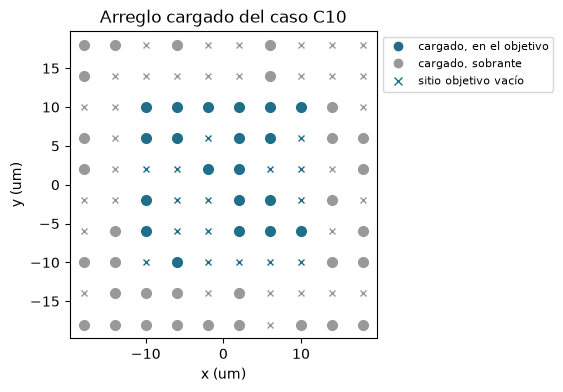

In [3]:
# los sitios: cargados o vacíos, dentro o fuera del bloque objetivo
xy = {i: (t["x_um"], t["y_um"]) for i, t in sites.items()}
fig, ax = plt.subplots(figsize=(5.4, 5.0))
for i, (x, y) in xy.items():
    inside, full = i in wanted, i in loaded
    ax.plot(x, y, "o" if full else "x", color="#1f6f8b" if inside else "#999999", markersize=7 if full else 5)
ax.plot([], [], "o", color="#1f6f8b", label="cargado, en el objetivo")
ax.plot([], [], "o", color="#999999", label="cargado, sobrante")
ax.plot([], [], "x", color="#1f6f8b", label="sitio objetivo vacío")
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_title("Arreglo cargado del caso C10")
ax.set_aspect("equal")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

El sorteo da 52 átomos cargados en los 100 sitios, 36 sitios objetivo de los cuales 16 están vacíos, y 32 átomos sobrantes fuera del bloque. Hay el doble de átomos sobrantes que de huecos, de modo que un bloque sin defectos es posible, y la pregunta es solo cuáles 16 de los 32 van adónde; si la carga hubiera dejado menos átomos que huecos, ninguna asignación podría llenar el bloque, y el método rechaza un caso con menos átomos que objetivos. La figura no muestra los 20 átomos cargados que ya están dentro del bloque y no necesitan moverse: forman parte de la asignación, con un camino de largo cero. También muestra que los átomos sobrantes están repartidos en el borde, así que las distancias a los huecos van de un sitio a varios.

## Método

### Paso 1: quién va adónde

El algoritmo húngaro (Kuhn y Munkres) encuentra el emparejamiento de los sitios objetivo con átomos distintos que minimiza un costo total. Para el reordenamiento, Lee, Kim y Ahn (2017) usan $C(f) = \sum_i d_{i,f(i)}^{\alpha}$ con $d$ la distancia entre el objetivo $t_i$ y el átomo $a_{f(i)}$. Con $\alpha = 1$ el costo es el largo total de caminos, y el óptimo puede enviar un átomo lejos si eso ahorra dos movimientos cortos en otra parte. Un $\alpha$ mayor penaliza más los movimientos largos que varios cortos, lo que reparte el trabajo, y los autores muestran que para una red cuadrada y $\alpha$ sobre cerca de 1,12 los caminos rectos de los átomos no se invaden entre sí. La suma recorre los 36 objetivos y los 52 átomos, así que un átomo que ya está en el bloque puede emparejarse con su propio sitio a costo cero. La celda calcula la asignación para seis exponentes e informa, en bins focales, el camino total, el movimiento más largo, el número de átomos que se mueven y el número de pares de caminos rectos que se cruzan o se superponen.

In [4]:
# la asignación para varios exponentes alpha del costo d^alpha, en bins focales: largo de caminos,
# movimiento más largo, cruces
bin_m = focal_bin_m(setup)
atoms_bins = np.array([[xy[i][0], xy[i][1]] for i in loaded]) * 1e-6 / bin_m
targets_bins = np.array([[xy[i][0], xy[i][1]] for i in wanted]) * 1e-6 / bin_m
plans = {}
for alpha in (0.5, 1.0, 1.2, 1.5, 2.0, 3.0):
    chosen = assign(targets_bins, atoms_bins, alpha)
    starts = atoms_bins[chosen]
    length = np.hypot(*(starts - targets_bins).T)
    plans[alpha] = (starts, length, count_crossings(starts, targets_bins))
    print(f"alpha {alpha:3.1f}: camino total {length.sum():6.1f} bins | movimiento más largo "
          f"{length.max():5.1f} bins | átomos que se mueven {int((length > 1e-9).sum()):2d} | "
          f"pares que se cruzan {plans[alpha][2]}")

alpha 0.5: camino total  264.1 bins | movimiento más largo  33.1 bins | átomos que se mueven 16 | pares que se cruzan 1
alpha 1.0: camino total  261.9 bins | movimiento más largo  29.0 bins | átomos que se mueven 16 | pares que se cruzan 0
alpha 1.2: camino total  267.1 bins | movimiento más largo  18.0 bins | átomos que se mueven 21 | pares que se cruzan 0
alpha 1.5: camino total  276.1 bins | movimiento más largo  18.0 bins | átomos que se mueven 24 | pares que se cruzan 1
alpha 2.0: camino total  293.6 bins | movimiento más largo  16.1 bins | átomos que se mueven 27 | pares que se cruzan 0
alpha 3.0: camino total  307.7 bins | movimiento más largo  16.1 bins | átomos que se mueven 30 | pares que se cruzan 0


La tabla tiene el compromiso que controla el exponente. De $\alpha = 1{,}0$ a $\alpha = 1{,}2$ el movimiento más largo baja de 29,0 a 18,0 bins, casi un sitio y medio menos en un bloque cuyos sitios están a 8 bins, mientras el camino total crece de 261,9 a 267,1 y el número de átomos que se mueven de 16 a 21. Más allá de 1,2 el movimiento más largo llega a un piso de 16,1 bins y el costo sigue subiendo: 276,1 bins con 1,5, 307,7 con 3,0, con 30 átomos en movimiento. El conteo de cruces no sigue al exponente de forma monótona: 1 par con 0,5, ninguno con 1,0 y 1,2, 1 par con 1,5, ninguno con 2,0 y 3,0. La figura siguiente dibuja los movimientos de dos de los exponentes, 1,0 y 1,5.

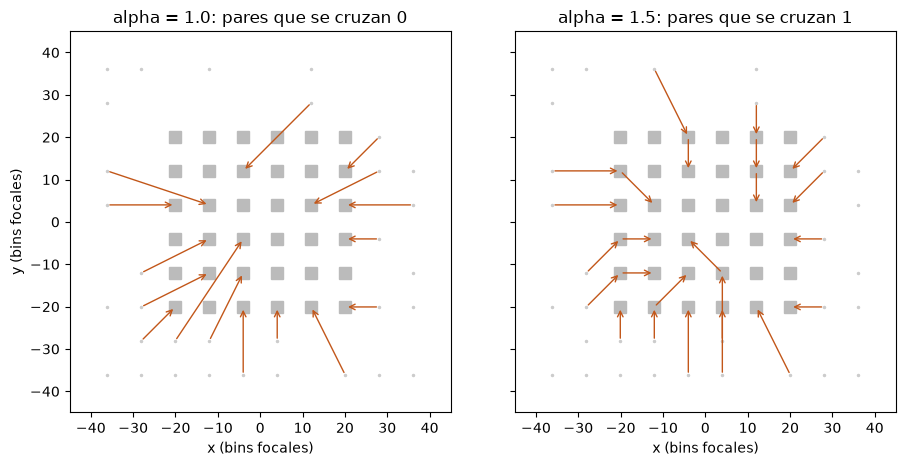

In [5]:
# los movimientos para alpha = 1.0 y alpha = 1.5: cada flecha va de un átomo al sitio objetivo que llena
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.6), sharey=True)
for ax, alpha in zip(axes, (1.0, 1.5)):
    starts, length, crossings = plans[alpha]
    ax.plot(*atoms_bins.T, ".", color="#cccccc", markersize=3)
    ax.plot(*targets_bins.T, "s", color="#bbbbbb", markersize=9)
    for s, e, d in zip(starts, targets_bins, length):
        if d > 1e-9:
            ax.annotate("", xy=e, xytext=s, arrowprops={"arrowstyle": "->", "color": "#c2571a", "linewidth": 1.0})
    ax.set_title(f"alpha = {alpha}: pares que se cruzan {crossings}")
    ax.set_xlabel("x (bins focales)")
    ax.set_xlim(-45, 45)
    ax.set_ylim(-45, 45)
    ax.set_aspect("equal")
axes[0].set_ylabel("y (bins focales)")
plt.tight_layout()
plt.show()

Con $\alpha = 1{,}0$ unos pocos átomos viajan lejos, las flechas que cruzan casi toda la figura, y el resto se queda quieto. Con $\alpha = 1{,}5$ se mueven más átomos y los movimientos son más cortos y más locales, cada uno llenando un hueco en su vecindad. Es lo que dijeron los números, y importa para el paso siguiente, porque el número de pasos de la secuencia lo fija el movimiento más largo. La figura no muestra el par que se cruza del plan con $\alpha = 1{,}5$, que es un par entre 276 bins de caminos y no se ve a este tamaño. Un cruce de dos caminos rectos no es una colisión por sí mismo: los átomos se mueven en paralelo y con la misma velocidad fraccionaria, así que se encuentran solo si están en el cruce al mismo tiempo. El conteo es una bandera conservadora, tal como la define el pipeline, y es la cantidad que se debe contrastar con la garantía del artículo para una red cuadrada. Para esta carga, con 32 átomos sobrantes y un bloque en el centro, el exponente de 1,5 no da cero: un par.

### Paso 2: lo que construye M16 a partir de la asignación

M16 es el método del producto que ejecuta la asignación húngara y luego construye los hologramas. Su plan es el mismo que da la tabla: lee los átomos y los sitios objetivo, asigna con el exponente que se le da, y fija el número de pasos a partir del movimiento más largo, $S = \lceil d_\text{máx} / s_\text{máx} \rceil$ con un paso $s_\text{máx}$ de dos bins. Ejecutarlo con un presupuesto pequeño de 8 iteraciones basta para leer el plan, porque el plan no depende de la luz. La celda lo ejecuta con el exponente 1,0.

In [6]:
# M16 sobre el mismo ordenamiento con exponente 1.0: el plan que construye con los mismos átomos y objetivos
atoms = build.trapset_of([sites[i] for i in loaded])
goal = Target.from_traps(build.trapset_of([sites[i] for i in wanted]))
plan = {1.0: m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=1.0)}
print(f"alpha 1.0: {plan[1.0].meta['n_steps']} pasos | {int(plan[1.0].meta['moved'].sum())} trampas en movimiento | "
      f"cruces {plan[1.0].meta['crossings']}")

alpha 1.0: 15 pasos | 16 trampas en movimiento | cruces 0


Con el exponente 1,0 el ordenamiento toma 15 pasos, porque su movimiento más largo es de 29,0 bins, y mueve 16 trampas, sin pares que se crucen, de acuerdo con la tabla. Sigue el mismo plan con el exponente de Lee, Kim y Ahn.

In [7]:
# el mismo plan con exponente 1.5
plan[1.5] = m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=1.5)
print(f"alpha 1.5: {plan[1.5].meta['n_steps']} pasos | {int(plan[1.5].meta['moved'].sum())} trampas en movimiento | "
      f"cruces {plan[1.5].meta['crossings']}")

alpha 1.5: 9 pasos | 24 trampas en movimiento | cruces 1


El exponente 1,5 necesita 9 pasos y mueve 24 trampas, y el plan contiene un par que se cruza, como decía la tabla. Las dos celdas siguientes ejecutan los exponentes 2,0 y 3,0.

In [8]:
# el mismo plan con exponente 2.0
plan[2.0] = m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=2.0)
print(f"alpha 2.0: {plan[2.0].meta['n_steps']} pasos | {int(plan[2.0].meta['moved'].sum())} trampas en movimiento | "
      f"cruces {plan[2.0].meta['crossings']}")

alpha 2.0: 9 pasos | 27 trampas en movimiento | cruces 0


El exponente 2,0 también toma 9 pasos, mueve 27 trampas y no tiene pares que se crucen.

In [9]:
# el mismo plan con exponente 3.0
plan[3.0] = m16_rearrangement.run(setup, goal, budget=Budget(8), rng=Rng(1), atoms=atoms, alpha=3.0)
print(f"alpha 3.0: {plan[3.0].meta['n_steps']} pasos | {int(plan[3.0].meta['moved'].sum())} trampas en movimiento | "
      f"cruces {plan[3.0].meta['crossings']}")

alpha 3.0: 9 pasos | 30 trampas en movimiento | cruces 0


Con el exponente 3,0 el plan mueve 30 trampas en 9 pasos y no tiene cruces. El número de pasos baja de 15 con el exponente 1,0 a 9 con todo exponente desde 1,5, porque el movimiento más largo baja de 29,0 a 18,0 y a 16,1 bins y el paso es de dos bins. Menos pasos significan menos hologramas por mostrar, y más trampas en movimiento significan más luz en movimiento que debe mantenerse brillante. Un ordenamiento es entonces una elección entre una secuencia larga con pocas trampas en movimiento y una corta con muchas, y el exponente es la perilla. El plan no dice cuán brillantes se mantienen las trampas mientras se mueven, lo que mide el notebook siguiente del tema, ni cómo cambiaría la elección con otra carga: este sorteo tiene 52 átomos para 36 objetivos, y una carga cercana al mínimo de 36 dejaría a la asignación sin libertad.

## Resultados

**Respuesta:** Los átomos se asignan con el algoritmo húngaro, que minimiza la suma de las distancias elevadas a un exponente $\alpha$, y el exponente no elimina por sí solo los cruces. En el caso C10 un sorteo de 52 átomos cargados deja 16 de los 36 sitios objetivo vacíos y 32 átomos sobrantes, de modo que el bloque puede llenarse por completo. Con $\alpha = 1{,}0$ el camino total es 261,9 bins, el movimiento más largo 29,0 bins, se mueven 16 átomos y ningún par de caminos se cruza; con $\alpha = 1{,}5$ el total es 276,1, el movimiento más largo 18,0, se mueven 24 átomos y se cruza un par. En seis exponentes el conteo de cruces es 1, 0, 0, 1, 0 y 0 para $\alpha$ = 0,5, 1,0, 1,2, 1,5, 2,0 y 3,0, así que el ordenamiento tiene a lo más un par que se cruza aquí, pero el exponente que recomienda el artículo no es el que no tiene ninguno. M16 convierte el plan en 15 pasos con $\alpha = 1{,}0$ y en 9 pasos desde 1,5.

Lo que el notebook no muestra es el ordenamiento sobre muchas cargas, ni la luz que mueve los átomos.

## Resumen

- El reordenamiento es un emparejamiento de costo mínimo de sitios objetivo con átomos cargados, resuelto con el algoritmo húngaro sobre el costo $d^\alpha$.
- Un exponente mayor acorta el movimiento más largo (29,0 bins con $\alpha = 1{,}0$, 18,0 con 1,2) al precio de un camino total más largo y más átomos en movimiento.
- El conteo de pares que se cruzan no es monótono en el exponente; $\alpha = 1{,}5$ deja un par con esta carga.
- M16 fija el número de pasos a partir del movimiento más largo: 15 con $\alpha = 1{,}0$, 9 desde 1,5.

## Referencias

- Lee, Kim and Ahn (2017). Defect-free atomic array formation using the Hungarian matching algorithm. Physical Review A 95, 053424. https://doi.org/10.1103/PhysRevA.95.053424
- Parallel assembly of neutral atom arrays with an SLM using linear phase interpolation. https://arxiv.org/abs/2501.01391